# Match Electride Registry Entries to Materials Project

This notebook creates three in-memory DataFrames and does not write or modify any CSV files:

- `matched_df`: rows with one or more matching MP entries
- `multiple_mpids_df`: rows with more than one matching MP ID
- `no_mpid_df`: rows with no matching MP entry

In [1]:
import os
import re
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from mp_api.client import MPRester
from pymatgen.core import Composition

BASE_DIR = Path.cwd()
if BASE_DIR.name != "enrichment":
    BASE_DIR = BASE_DIR / "data" / "electrides" / "enrichment"
REGISTRY_PATH = BASE_DIR / "inorganic_electride_registry_enriched.csv"
PROJECT_DIR = BASE_DIR.parents[2]
load_dotenv(PROJECT_DIR / ".env")

FORMULA_COLUMN = "normalized_formula"
SPACE_GROUP_COLUMN = "space_group"
EXISTING_MP_COLUMN = "materials_project_id"


/opt/anaconda3/envs/electride-ml/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
registry_df = pd.read_csv(REGISTRY_PATH)
required_columns = {FORMULA_COLUMN, SPACE_GROUP_COLUMN, EXISTING_MP_COLUMN}
missing_columns = required_columns - set(registry_df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

print(f"Loaded {len(registry_df)} registry entries.")
display(registry_df[[FORMULA_COLUMN, SPACE_GROUP_COLUMN, EXISTING_MP_COLUMN]].head())

Loaded 463 registry entries.


,normalized_formula,space_group,materials_project_id
0,AsLi7,P6/mmm,not reported
1,AsLi7,Pmmm,not reported
2,Ba2As,I4/mmm,not reported
3,Ba2Bi,I4/mmm,not reported
4,Ba2CrN5,C2/m,not reported


## Matching helpers

In [3]:
def normalized_space_group(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.lower() in {"", "not reported", "nan", "none"}:
        return None
    return value.replace(" ", "").replace("_", "").replace("−", "-")

def existing_mpids(value):
    if pd.isna(value):
        return []
    return re.findall(r"mp-\d+", str(value))

def same_formula(left, right):
    try:
        return Composition(left).reduced_composition == Composition(right).reduced_composition
    except (TypeError, ValueError):
        return False

def queryable_formula(value):
    try:
        composition = Composition(value)
        return len(composition.elements) > 0 and all(amount > 0 for amount in composition.values())
    except (TypeError, ValueError):
        return False

def matching_mp_docs(docs, formula, space_group):
    target_space_group = normalized_space_group(space_group)
    if target_space_group is None:
        return []

    matches = []
    for doc in docs:
        doc_space_group = getattr(getattr(doc, "symmetry", None), "symbol", None)
        if same_formula(formula, getattr(doc, "composition", None)) and normalized_space_group(doc_space_group) == target_space_group:
            matches.append(doc)
    return matches

## Query Materials Project and build the DataFrames

In [4]:
MP_API_KEY = os.environ.get("MP_API_KEY")
if not MP_API_KEY:
    raise RuntimeError("Set MP_API_KEY before running the Materials Project query.")

query_cache = {}
matched_rows = []
multiple_rows = []
no_match_rows = []

with MPRester(MP_API_KEY) as mpr:
    for _, row in registry_df.iterrows():
        formula = row[FORMULA_COLUMN]
        space_group = row[SPACE_GROUP_COLUMN]
        existing_ids = existing_mpids(row[EXISTING_MP_COLUMN])

        output_row = row.to_dict()
        output_row["existing_mp_id"] = ", ".join(existing_ids)

        if not queryable_formula(formula):
            output_row["no_match_reason"] = "invalid_or_variable_formula_for_mp_query"
            output_row["mp_id_candidates"] = ""
            no_match_rows.append(output_row)
            continue

        if formula not in query_cache:
            query_cache[formula] = mpr.materials.summary.search(
                formula=formula,
                all_fields=False,
                fields=["material_id", "formula_pretty", "composition", "symmetry"],
            )

        matches = matching_mp_docs(query_cache[formula], formula, space_group)
        candidate_ids = [str(doc.material_id) for doc in matches]
        output_row["mp_id_candidates"] = ", ".join(candidate_ids)
        output_row["mp_id_verification"] = (
            "verified" if existing_ids and set(existing_ids).intersection(candidate_ids)
            else "mismatch" if existing_ids
            else "new_match"
        )

        if len(candidate_ids) == 0:
            output_row["no_match_reason"] = (
                "space_group_not_reported"
                if normalized_space_group(space_group) is None
                else "no_formula_and_space_group_match"
            )
            no_match_rows.append(output_row)
        elif len(candidate_ids) > 1:
            output_row["multiple_match_count"] = len(candidate_ids)
            multiple_rows.append(output_row)
        else:
            output_row["mp_id"] = candidate_ids[0]
            matched_rows.append(output_row)

matched_df = pd.DataFrame(matched_rows)
multiple_mpids_df = pd.DataFrame(multiple_rows)
no_mpid_df = pd.DataFrame(no_match_rows)

print(f"Unique matches: {len(matched_df)}")
print(f"Multiple-MPID matches: {len(multiple_mpids_df)}")
print(f"No matches: {len(no_mpid_df)}")
print(f"Partition total: {len(matched_df) + len(multiple_mpids_df) + len(no_mpid_df)}")

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 1/1 [00:00<00:00, 10645.44it/s]

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 1/1 [00:00<00:00, 16448.25it/s]

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 1/1 [00:00<00:00, 15650.39it/s]

... (671 outputs left out)

Retrieving SummaryDoc documents: 100%|██████████| 2/2 [00:00<00:00, 42581.77it/s]

Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 2/2 [00:00<00:00, 45343.83it/s]

Unique matches: 341
Multiple-MPID matches: 13
No matches: 109
Partition total: 463


## Verification summary

In [5]:
assert len(matched_df) + len(multiple_mpids_df) + len(no_mpid_df) == len(registry_df)
assert matched_df["mp_id"].notna().all()

if len(multiple_mpids_df):
    display(multiple_mpids_df[["record_id", FORMULA_COLUMN, SPACE_GROUP_COLUMN, "mp_id_candidates", "existing_mp_id"]])

if len(no_mpid_df):
    display(no_mpid_df[["record_id", FORMULA_COLUMN, SPACE_GROUP_COLUMN, "no_match_reason", "existing_mp_id"]].head(20))

verification_counts = matched_df["mp_id_verification"].value_counts(dropna=False)
print("Verification status among unique matches:")
display(verification_counts.to_frame("count"))

,record_id,normalized_formula,space_group,mp_id_candidates,existing_mp_id
0,ELD-0042,BaSi,Cmcm,"mp-1237266, mp-2499",mp-2499
1,ELD-0211,LaScSi,I4/mmm,"mp-1024951, mp-1025119",
2,ELD-0243,Na,P63/mmc,"mp-982370, mp-999501, mp-10172",
3,ELD-0265,Nd5Ge3,P63/mcm,"mp-1464, mp-1465",
4,ELD-0266,Nd5Ge3,P63/mcm,"mp-1464, mp-1465",mp-1464
5,ELD-0282,NdScSi,I4/mmm,"mp-1077558, mp-1207147",
6,ELD-0283,NdScSi,I4/mmm,"mp-1077558, mp-1207147",mp-1077558
7,ELD-0308,PrScSi,I4/mmm,"mp-1024960, mp-1206584",
8,ELD-0309,PrScSi,I4/mmm,"mp-1024960, mp-1206584",mp-1024960
9,ELD-0326,Sc5Si3,P63/mcm,"mp-1190215, mp-7822",


,record_id,normalized_formula,space_group,no_match_reason,existing_mp_id
0,ELD-0001,AsLi7,P6/mmm,no_formula_and_space_group_match,
1,ELD-0002,AsLi7,Pmmm,no_formula_and_space_group_match,
2,ELD-0005,Ba2CrN5,C2/m,no_formula_and_space_group_match,
3,ELD-0009,Ba2N,Cc,no_formula_and_space_group_match,
4,ELD-0018,Ba3N,P63/mmc,no_formula_and_space_group_match,
5,ELD-0025,Ba5Ge3,I4/mcm,no_formula_and_space_group_match,
6,ELD-0028,Ba5Si3,I4/mcm,no_formula_and_space_group_match,
7,ELD-0034,BaAl2O4-xHy,not reported,invalid_or_variable_formula_for_mp_query,
8,ELD-0035,BaAl2O4-y,not reported,invalid_or_variable_formula_for_mp_query,
9,ELD-0036,BaBr,P-62,no_formula_and_space_group_match,


Verification status among unique matches:


,count
mp_id_verification,
new_match,219
verified,122


In [6]:
from pymatgen.core import Composition

summary_df = matched_df.copy()

summary_df["formula_skeleton"] = summary_df["normalized_formula"].apply(
    lambda formula: Composition(formula).anonymized_formula
)

formula_skeleton_summary = (
    summary_df
    .groupby("formula_skeleton")
    .agg(
        structure_count=("mp_id", "count"),
        unique_formula_count=("normalized_formula", "nunique"),
        unique_mp_id_count=("mp_id", "nunique"),
    )
    .reset_index()
    .sort_values("structure_count", ascending=False)
)

space_group_summary = (
    summary_df
    .groupby(["space_group", "space_group_number_enriched"], dropna=False)
    .agg(
        structure_count=("mp_id", "count"),
        unique_formula_count=("normalized_formula", "nunique"),
        unique_mp_id_count=("mp_id", "nunique"),
    )
    .reset_index()
    .sort_values("structure_count", ascending=False)
)

print("Formula skeleton distribution:")
display(formula_skeleton_summary)

print("Space group distribution:")
display(space_group_summary)

Formula skeleton distribution:


,formula_skeleton,structure_count,unique_formula_count,unique_mp_id_count
10,A3B5,75,67,71
19,AB2C2,58,49,49
18,AB2,44,40,40
26,ABC,38,30,31
17,AB,32,28,30
22,AB3,30,30,30
29,ABC4,11,11,11
2,A2B3,10,9,9
27,ABC2,8,6,6
23,AB3C3,5,5,5


Space group distribution:


,space_group,space_group_number_enriched,structure_count,unique_formula_count,unique_mp_id_count
20,P4/mbm,127,59,50,50
27,P63/mcm,193,57,53,53
12,I4/mmm,139,35,29,29
28,P63/mmc,194,22,21,21
35,R-3m,166,21,20,20
21,P4/nmm,129,15,14,14
11,I4/mcm,140,14,14,14
30,Pm-3m,221,14,14,14
32,Pnma,62,13,12,12
3,Cmcm,63,12,12,12


In [7]:
no_mpid_df

,material_id,normalized_formula,formula_as_reported,material_name,electride_status,confidence,electride_dimensionality,material_category,crystal_structure_or_prototype,space_group,...,conditions_claim_source_type,electride_evidence_location,electride_evidence_summary,electride_claim_source_type,additional_sources_enriched,enrichment_notes,existing_mp_id,mp_id_candidates,mp_id_verification,no_match_reason
0,ELD-0001,AsLi7,AsLi7,not reported,theoretically_predicted,high,0D,intermetallic or Zintl-like electride,not reported,P6/mmm,...,primary_literature; inference explicitly labeled,Primary article and Supporting Information; or...,Structure search and ELF/topological electroni...,primary_literature,not reported,Original fields were preserved; added structur...,,,new_match,no_formula_and_space_group_match
1,ELD-0002,AsLi7,AsLi7,not reported,theoretically_predicted,high,1D,intermetallic or Zintl-like electride,not reported,Pmmm,...,primary_literature; inference explicitly labeled,Primary article and Supporting Information; or...,Structure search and ELF/topological electroni...,primary_literature,not reported,Original fields were preserved; added structur...,,,new_match,no_formula_and_space_group_match
2,ELD-0005,Ba2CrN5,Ba2CrN5,not reported,theoretically_predicted,high,0D,nitride or subnitride electride,space-group No. 12 database phase,C2/m,...,primary_literature; inference explicitly labeled,"Supporting Information, Table S1, pp. 5–10, se...",Supporting Table S1 identifies this phase as a...,supplementary_information; primary_literature,https://acs.figshare.com/articles/journal_cont...,The database provenance is literature-supporte...,,,new_match,no_formula_and_space_group_match
3,ELD-0009,Ba2N,Ba2N,not reported,theoretically_predicted,high,0D,nitride or subnitride electride,not reported,Cc,...,primary_literature; inference explicitly labeled,Primary article and Supporting Information; or...,"Structure search, ELF, and electronic structur...",primary_literature,not reported,Original fields were preserved; added structur...,,,new_match,no_formula_and_space_group_match
4,ELD-0018,Ba3N,Ba3N,not reported,theoretically_predicted,high,1D,nitride or subnitride electride,space-group No. 194 database phase,P63/mmc,...,primary_literature; inference explicitly labeled,"Supporting Information, Table S1, pp. 5–10, se...",Supporting Table S1 identifies this phase as a...,supplementary_information; primary_literature,Computational Screening of Electrides from Ino...,The database provenance is literature-supporte...,,,new_match,no_formula_and_space_group_match
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,ELD-0445,YBr,YBr,not reported,theoretically_predicted,high,0D,halide electride,space-group No. 166 database phase,R-3m,...,primary_literature; inference explicitly labeled,"Supporting Information, Table S1, pp. 5–10, se...",Supporting Table S1 identifies this phase as a...,supplementary_information; primary_literature,https://acs.figshare.com/articles/journal_cont...,The database provenance is literature-supporte...,,,new_match,no_formula_and_space_group_match
105,ELD-0450,YMgSn,YMgSn,not reported,theoretically_predicted,high,0D,intermetallic or Zintl-like electride,space-group No. 189 database phase,P-62m,...,primary_literature; inference explicitly labeled,"Supporting Information, Table S1, pp. 5–10, se...",Supporting Table S1 identifies this phase as a...,supplementary_information; primary_literature,https://acs.figshare.com/articles/journal_cont...,The database provenance is literature-supporte...,,,new_match,no_formula_and_space_group_match
106,ELD-0451,YScSb,YScSb,not reported,theoretically_predicted,high,0D,intermetallic or Zintl-like electride,space-group No. 139 database phase,I4/mmm,...,primary_literature; inference explicitly labeled,"Supporting Information, Table S1, pp. 5–10, se...",Supporting Table S1 identifies this phase as a...,supplementary_information; primary_literature,https:/

## Distribution of matched formula skeletons and space groups

Formula skeleton distribution:


,formula_skeleton,structure_count
0,A3B5,75
1,AB2C2,58
2,AB2,44
3,ABC,38
4,AB,32
5,AB3,30
6,ABC4,11
7,A2B3,10
8,ABC2,8
9,AB3C3,5


Space group distribution:


,space_group,structure_count
0,P4/mbm,59
1,P63/mcm,57
2,I4/mmm,35
3,P63/mmc,22
4,R-3m,21
5,P4/nmm,15
6,I4/mcm,14
7,Pm-3m,14
8,Pnma,13
9,Cmcm,12


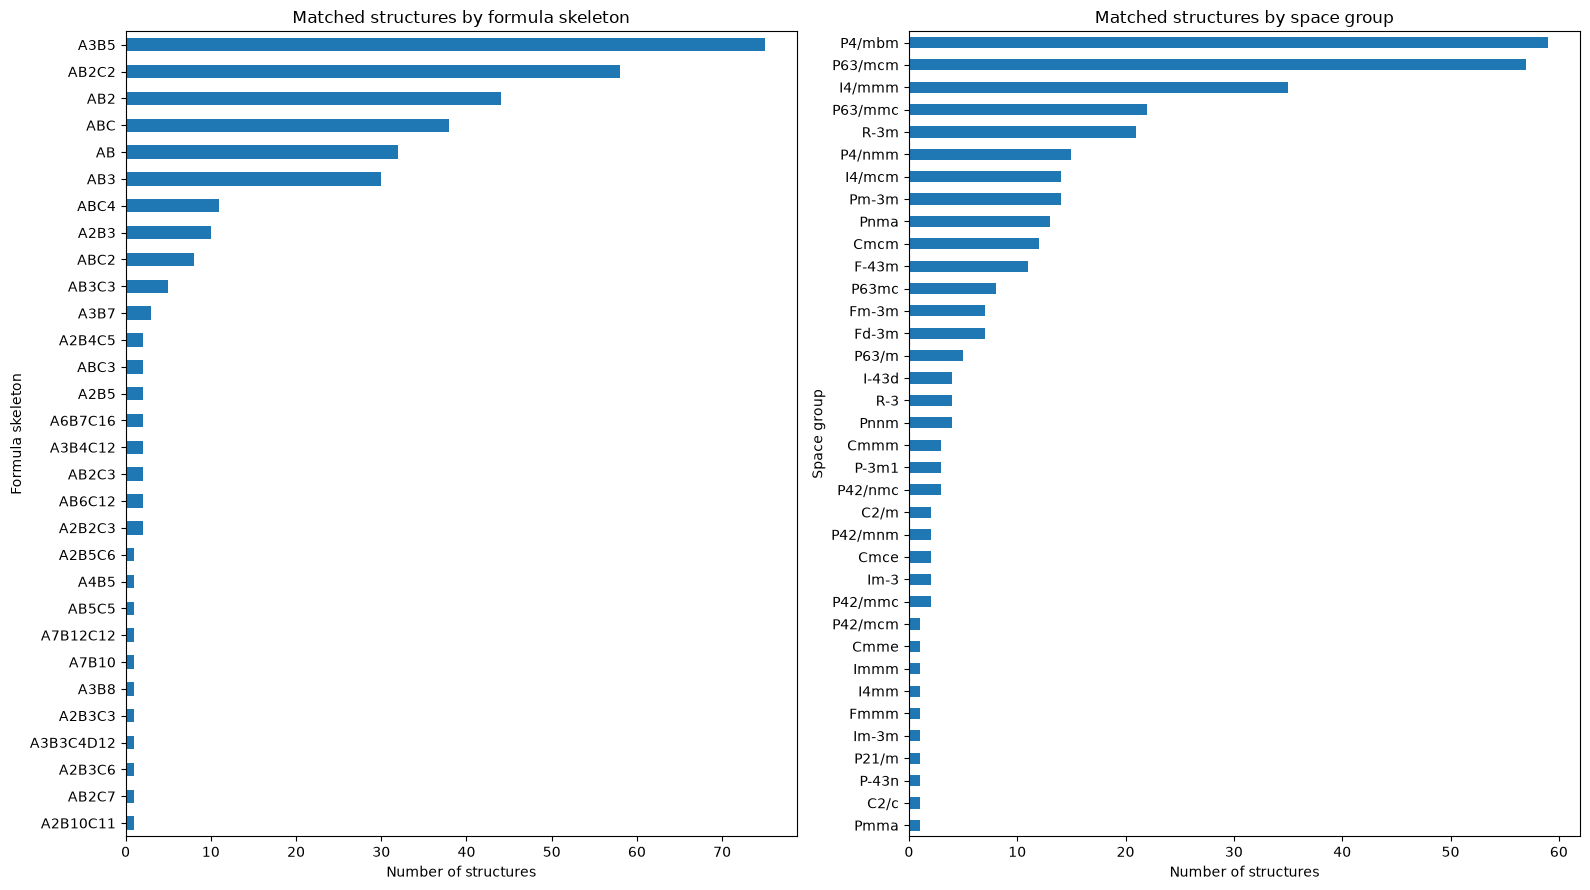

In [8]:
import matplotlib.pyplot as plt
from pymatgen.core import Composition

summary_df = matched_df.copy()
summary_df["formula_skeleton"] = summary_df["normalized_formula"].apply(
    lambda formula: Composition(formula).anonymized_formula
)

formula_skeleton_summary = (
    summary_df["formula_skeleton"]
    .value_counts()
    .rename_axis("formula_skeleton")
    .reset_index(name="structure_count")
)

space_group_summary = (
    summary_df["space_group"]
    .value_counts()
    .rename_axis("space_group")
    .reset_index(name="structure_count")
)

print("Formula skeleton distribution:")
display(formula_skeleton_summary)
print("Space group distribution:")
display(space_group_summary)

formula_plot = formula_skeleton_summary.sort_values("structure_count")
space_group_plot = space_group_summary.sort_values("structure_count")

fig, axes = plt.subplots(1, 2, figsize=(16, max(7, 0.25 * max(len(formula_plot), len(space_group_plot)))))
formula_plot.plot.barh(
    x="formula_skeleton", y="structure_count", ax=axes[0], legend=False
)
axes[0].set_title("Matched structures by formula skeleton")
axes[0].set_xlabel("Number of structures")
axes[0].set_ylabel("Formula skeleton")

space_group_plot.plot.barh(
    x="space_group", y="structure_count", ax=axes[1], legend=False
)
axes[1].set_title("Matched structures by space group")
axes[1].set_xlabel("Number of structures")
axes[1].set_ylabel("Space group")

plt.tight_layout()
plt.show()

## Save the single-match dataset

In [9]:
FINAL_DATASET_DIR = BASE_DIR.parent / "final_dataset"
FINAL_DATASET_DIR.mkdir(exist_ok=True)
FINAL_DATASET_PATH = FINAL_DATASET_DIR / "inorganic_electride_registry_matched.csv"
matched_df.to_csv(FINAL_DATASET_PATH, index=False)
print(f"Saved {len(matched_df)} unique-match rows to {FINAL_DATASET_PATH}")

Saved 341 unique-match rows to /Users/andrewweiland/Andrews_Lab_Research/electride-ml-predictor/data/electrides/final_dataset/inorganic_electride_registry_matched.csv
